In [1]:
%load_ext watermark


In [2]:
import itertools as it

from IPython.display import display
from matplotlib import pyplot as plt
import numpy as np
import pandas as pd
import polars as pl
from scipy import stats as scipy_stats
import seaborn as sns
from teeplot import teeplot as tp
from tqdm import tqdm

from pylib._osf_fetch import osf_fetch
from pylib.theory._calc_drift_fixprob import calc_drift_fixprob
from pylib.theory._calc_hitchhike_prob_closed import calc_hitchhike_prob_closed
from pylib.theory._calc_hold_prob import calc_hold_prob
from pylib.theory._calc_load_params import calc_load_params
from pylib.theory._calc_mutator_fixprob import calc_mutator_fixprob
from pylib.theory._calc_mutator_fixprob_closed import (
    calc_mutator_fixprob_closed,
)
from pylib.theory._calc_ncrit import calc_ncrit
from pylib.theory._calc_ncrit_closed import calc_ncrit_closed
from pylib.theory._resimulate_wellmixed import resimulate_wellmixed


In [3]:
%watermark -diwmuv -iv


Last updated: 2026-11-26T02:15:45.192383+00:00

Python implementation: CPython
Python version       : 3.10.22
IPython version      : 7.31.1

Compiler    : GCC 13.3.0
OS          : Linux
Release     : 7.0.0-1017-azure
Machine     : x86_64
Processor   : x86_64
CPU cores   : 4
Architecture: 64bit

pandas    : 2.2.3
scipy     : 1.14.1
polars    : 1.9.0
matplotlib: 3.9.2
seaborn   : 0.13.2
numpy     : 2.1.2
teeplot   : 1.2.0

Watermark: 2.4.3



In [4]:
teeplot_subdir = "theory-5050-npfix"
teeplot_subdir


'theory-5050-npfix'

# Predicting 50/50 $N P_\mathrm{fix}$ and $N_\mathrm{crit}$ with limited adaptive potential

This notebook extends the heuristic of [Raynes et al. (2018)](https://doi.org/10.1073/pnas.1715996115) to predict mutator fixation probability in 50/50 competitions, as a function of population size $N$, adaptive potential $K$ (number of available beneficial mutations), and population structure.

$P_\mathrm{fix}$ is the mutator fixation probability and $x_0 = 1/2$ the initial mutator frequency.
Normalized fixation probability is $N P_\mathrm{fix} \equiv P_\mathrm{fix} / x_0$, so $N P_\mathrm{fix} = 1$ is a 50/50 outcome.
$N_\mathrm{crit}$ is a population size where $N P_\mathrm{fix}$ crosses 1.

## The model in brief

$$P_\mathrm{fix}(N, K) = \underbrace{P_\mathrm{escape}(N)}_{\text{mutators outrun their load}} \times \underbrace{[1 - P_\mathrm{catchup}(N, K)]}_{\text{nonmutators never catch up}}$$

Everything is built from two rates, at which nonmutators and mutators found established beneficial clones, per individual per generation,

$$u_n = U_b\,p, \qquad u_m = M U_b\, q_0\, p,$$

and from the indirect cost of being a mutator, its excess deleterious mutation rate $\delta$.
Here $p = 1 - e^{-2s}$ is the probability a beneficial mutation establishes (the large-population limit of Kimura's fixation probability, as in Raynes et al.) and $q_0$ is the fraction of mutators free of deleterious mutations; mutators' load enters their supply through $q_0$ alone, so $u_m / u_n = M q_0$.

**1. Escape (lower $N_\mathrm{crit}$).**
Loaded mutators decline logistically at rate $\delta$.
The chance that at least one founds an established beneficial clone first is

$$P_\mathrm{hitchhiking} = 1 - (1 - x_0)^{N / N_\mathrm{crit}^{-}}, \qquad N_\mathrm{crit}^{-} = \frac{\delta}{u_m}.$$

Setting $x_0 = 1/N$ recovers Raynes et al. eq. 1c, and $P_\mathrm{hitchhiking} = x_0$ exactly at $N = N_\mathrm{crit}^{-}$ for every $x_0$: their $N_\mathrm{crit}$ carries over unchanged to competitions from any starting frequency.
Drift adds Kimura's $P_\mathrm{drift}$, so $P_\mathrm{escape} = P_\mathrm{drift} + (1 - P_\mathrm{drift}) P_\mathrm{hitchhiking}$.

**2. Sweep time.**
A fitness class whose clones are founded at rate $u$ per individual, and grow at rate $r$, reaches a given location after a mean time

$$T_\text{well-mixed} = \frac{\ln(p\, r / u) - \gamma}{r}, \qquad T_\text{2D} = \Gamma(\tfrac{4}{3}) \left[\frac{3}{\pi\, u\, n\, v^2}\right]^{1/3} + \frac{\ln(n\, p)}{r},$$

for a well-mixed population and for a 2D lattice of $n$-agent demes across which clones spread at speed $v = r / \ln(n r)$.
This is the only place population structure enters.

**3. Share law.**
Equal-fitness mutators and nonmutators compete on equal terms, so each new fitness class is divided between them in proportion to the rates at which they found it.
Nonmutators' odds in class $k$, and from them their share, are

$$o_k = \frac{1 - x_0}{x_0}\, P_\mathrm{hitchhiking} \left(\frac{u_n}{u_m}\right)^{k}, \qquad a_k = \frac{o_k}{1 + o_k}.$$

The factor $P_\mathrm{hitchhiking}$ conditions mutators' supply on their having escaped; it is one for a start at appreciable frequency in a large population, where $a_k \approx o_k$, and matters for a single invader, $x_0 = 1/N$.

**4. Catch-up (upper $N_\mathrm{crit}$).**
With adaptive potential capped at $K$, mutators climb to the peak and stall, still carrying their load, so any nonmutator lineage that also establishes there takes over.
Nonmutators one step below the peak have a sweep time $T = T(u_m)$ in which to do so, the same for every $K$:

$$P_\mathrm{catchup} = 1 - \exp(-N\, u_n\, a_{K-1}\, T), \qquad N_\mathrm{crit}^{+}(K) = \frac{\ln(1/x_0)}{u_n\, a_{K-1}\, T}.$$

Each further available beneficial mutation raises $N_\mathrm{crit}^{+}$ by $u_m / u_n$, about the mutator strength $M$.
With unlimited adaptive potential there is no upper threshold.

These closed forms are `calc_mutator_fixprob_closed` and `calc_ncrit_closed`.
Curves labeled "numerical" below come from `calc_mutator_fixprob`, which treats drift and hitchhiking jointly as a diffusion and replaces steps 2 to 4 with a branching-process recursion; it is well-mixed only and serves as a check on the closed forms.

## Model, as simulated

Parameters are read off the simulation source (`wse-sketches`: `pylib/_hypermutator_5050.py`, `cerebraslib/genome_hypermutator*.csl`): nonmutator $U_b = 10^{-6}$, $U_d = 10^{-4}$; mutator rates $M = 100$ times higher; tournament size 1.1.
Each offspring slot is filled by the better of two random parents with probability $s = 0.1$, else by a random parent, so selection is rank-based: being ahead by one mutation or by five is worth the same $s$.


## Theory: Derived Quantities


In [5]:
params = calc_load_params()
params


{'delta': np.float64(0.00985017125066523),
 'q0': np.float64(0.9004983374916811),
 'pi_mut': np.float64(0.18126924692201815),
 'pi_non': np.float64(0.18126924692201815),
 'growth_non': 0.1,
 'growth_mut': np.float64(0.09014982874933478),
 'supply_non': np.float64(1.8126924692201815e-07),
 'supply_mut': np.float64(1.6323265549164637e-05),
 'N_hitch': np.float64(603.4436688539521)}

In [6]:
Ks = [1, 2, 3, 4, 5, np.inf]
df_ncrit_theory = pd.DataFrame(
    [
        {
            "available beneficial mutations": K,
            "C_K": (
                calc_hold_prob(1e12, int(K), finite_wave=False)[1]
                if np.isfinite(K)
                else 0.0
            ),
            "lower Ncrit": calc_ncrit(K, "lower"),
            "upper Ncrit": calc_ncrit(K, "upper"),
        }
        for K in tqdm(Ks)
    ],
)
df_ncrit_theory


100%|██████████| 6/6 [00:37<00:00,  6.17s/it]


,available beneficial mutations,C_K,lower Ncrit,upper Ncrit
0,1.0,6.091776e+00,605.011332,1.160162e+05
1,2.0,1.430616e-01,603.468467,4.783277e+06
2,3.0,1.638411e-03,603.453930,4.202969e+08
3,4.0,2.287620e-05,603.452300,3.013779e+10
4,5.0,3.254619e-07,603.452000,2.121412e+12
5,inf,0.000000e+00,603.443669,NaN


In [7]:
log_Ns = np.arange(1.5, 10.01, 0.125)
df_theory = pd.DataFrame(
    [
        {
            "population size": 10**log_N,
            "available beneficial mutations": K,
            "fixation probability": calc_mutator_fixprob(10**log_N, K),
        }
        for K, log_N in tqdm([*it.product(Ks, log_Ns)])
    ],
)
df_theory["NPfix"] = df_theory["fixation probability"] / 0.5
df_theory


100%|██████████| 414/414 [00:23<00:00, 17.51it/s]


,population size,available beneficial mutations,fixation probability,NPfix
0,3.162278e+01,1.0,0.427386,0.854772
1,4.216965e+01,1.0,0.406110,0.812220
2,5.623413e+01,1.0,0.380500,0.761000
3,7.498942e+01,1.0,0.351597,0.703193
4,1.000000e+02,1.0,0.322531,0.645063
...,...,...,...,...
409,3.162278e+09,inf,1.000000,2.000000
410,4.216965e+09,inf,1.000000,2.000000
411,5.623413e+09,inf,1.000000,2.000000
412,7.498942e+09,inf,1.000000,2.000000


## Theory: Decomposition

Counterpart to Figure 1 of Raynes et al. (2018), for a 50/50 start.


/home/runner/work/hypermutator-dynamics/hypermutator-dynamics/binder/pylib/theory/_calc_drift_fixprob.py:15: RuntimeWarning: overflow encountered in expm1
  return float(np.expm1(a * x0) / np.expm1(a))


teeplots/theory-5050-npfix/num-abm=1+viz=plot-decomposition+ext=.pdf
teeplots/theory-5050-npfix/num-abm=1+viz=plot-decomposition+ext=.png


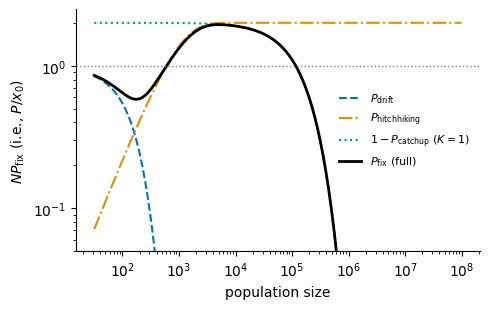

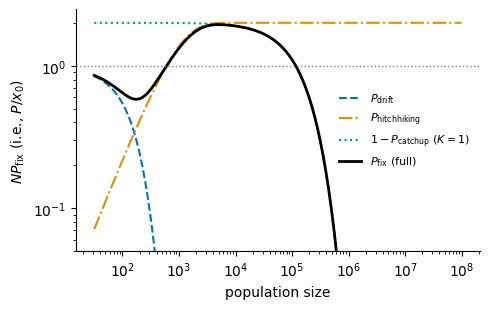

In [8]:
def plot_decomposition(K: int) -> plt.Figure:
    Ns = 10 ** np.arange(1.5, 8.01, 0.05)
    fig, ax = plt.subplots(figsize=(5, 3.2))
    curves = {
        r"$P_\mathrm{drift}$": [calc_drift_fixprob(N) for N in Ns],
        r"$P_\mathrm{hitchhiking}$": [
            calc_hitchhike_prob_closed(N) for N in Ns
        ],
        rf"$1 - P_\mathrm{{catchup}}$ ($K={K}$)": [
            calc_hold_prob(N, K)[0] for N in Ns
        ],
    }
    palette = sns.color_palette("colorblind")
    for (label, ys), color, ls in zip(
        curves.items(), palette, ["--", "-.", ":"]
    ):
        ax.plot(Ns, np.array(ys) / 0.5, label=label, color=color, ls=ls)
    ax.plot(
        Ns,
        [calc_mutator_fixprob(N, K) / 0.5 for N in Ns],
        color="black",
        lw=2,
        label=r"$P_\mathrm{fix}$ (full)",
    )
    ax.axhline(1.0, color="gray", lw=1, ls=":")
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_ylim(0.05, 2.5)
    ax.set_xlabel("population size")
    ax.set_ylabel(r"$N P_\mathrm{fix}$ (i.e., $P / x_0$)")
    ax.legend(frameon=False, fontsize=8)
    sns.despine(fig)
    fig.tight_layout()
    return fig


tp.tee(
    plot_decomposition,
    K=1,
    teeplot_outattrs={"num-abm": 1},
    teeplot_subdir=teeplot_subdir,
)


## Prep Data


In [9]:
def load_fixprobs(url: str, nben: object) -> pl.DataFrame:
    """Tabulate mutator fixation per replicate population, from tile-level
    trait counts."""
    df = pl.from_pandas(pd.read_parquet(osf_fetch(url)))
    if nben is None:
        df = df.with_columns(pl.col("nBen").cast(pl.Float64).alias("K"))
    else:
        df = df.with_columns(pl.lit(float(nben)).alias("K"))
    df = df.with_columns(
        pl.when(pl.col("nRowSubgrid") == 0)
        .then(pl.col("nRow"))
        .otherwise(pl.col("nRowSubgrid"))
        .cast(pl.UInt64)
        .alias("nRowSubgrid"),
        pl.when(pl.col("nColSubgrid") == 0)
        .then(pl.col("nCol"))
        .otherwise(pl.col("nColSubgrid"))
        .cast(pl.UInt64)
        .alias("nColSubgrid"),
    ).with_columns(
        (pl.col("row").cast(pl.UInt64) // pl.col("nRowSubgrid")).alias(
            "rowGroup"
        ),
        (pl.col("col").cast(pl.UInt64) // pl.col("nColSubgrid")).alias(
            "colGroup"
        ),
        (
            pl.col("nColSubgrid")
            * pl.col("nRowSubgrid")
            * pl.col("tilePopSize").cast(pl.UInt64)
        ).alias("population size"),
    )
    is_mut = pl.col("trait value") == 1
    return (
        df.group_by(
            ["replicate", "K", "population size", "rowGroup", "colGroup"],
        )
        .agg(
            (
                pl.col("trait count").filter(is_mut).sum()
                / pl.col("tilePopSize").filter(is_mut).sum()
            ).alias("fixation probability"),
            # generation when last nonmutator was seen
            pl.col("trait cycle last seen")
            .filter(~is_mut)
            .max()
            .alias("fixation time"),
            (
                is_mut.sum()
                == pl.col("nRowSubgrid").first()
                * pl.col("nColSubgrid").first()
            ).alias("is complete"),
        )
        .filter(pl.col("is complete"))  # drop partial subgrids at fabric edge
        .select(
            ["K", "population size", "fixation probability", "fixation time"]
        )
    )


In [10]:
sources = [
    ("well-mixed (GPU)", "https://osf.io/duam2/download", None),
    ("2D, 256/deme (GPU)", "https://osf.io/8q5v6/download", None),
    ("2D, 32/deme (WSE)", "https://osf.io/p4tyb/download", np.inf),
    ("2D, 32/deme (WSE)", "https://osf.io/93rdk/download", 1),
    ("2D, 32/deme (WSE)", "https://osf.io/fahu9/download", 2),
    ("2D, 32/deme (WSE)", "https://osf.io/2wxmb/download", 3),
    ("2D, 32/deme (WSE)", "https://osf.io/ra2fw/download", 4),
    ("2D, 32/deme (WSE)", "https://osf.io/6ek82/download", 5),
    ("2D, 2048/deme (WSE)", "https://osf.io/qfdsh/download", np.inf),
    ("2D, 2048/deme (WSE)", "https://osf.io/cu9r6/download", 1),
    ("2D, 2048/deme (WSE)", "https://osf.io/ngdqw/download", 2),
    ("2D, 2048/deme (WSE)", "https://osf.io/mb5x8/download", 3),
    ("2D, 2048/deme (WSE)", "https://osf.io/g2ake/download", 4),
    ("2D, 2048/deme (WSE)", "https://osf.io/3mgcr/download", 5),
]
dfs = []
for treatment, url, nben in tqdm(sources):
    dfs.append(
        load_fixprobs(url, nben).with_columns(
            pl.lit(treatment).alias("treatment")
        ),
    )

# 2D, 256/deme (WSE) is published pre-tabulated
dfs.append(
    pl.from_pandas(pd.read_parquet(osf_fetch("https://osf.io/bhk27/download")))
    .filter(pl.col("trait value") == 1)
    .select(
        pl.col("available beneficial mutations").cast(pl.Float64).alias("K"),
        pl.col("population size").cast(pl.UInt64),
        pl.col("fixation probability"),
        pl.lit(None, dtype=pl.Int64).alias("fixation time"),
        pl.lit("2D, 256/deme (WSE)").alias("treatment"),
    ),
)
df_reps = pl.concat(
    [df.select(dfs[0].columns) for df in dfs], how="vertical_relaxed"
)
df_reps


  0%|          | 0/14 [00:00<?, ?it/s]

downloading https://osf.io/duam2/download -> /tmp/duam2
size: 25587641 bytes


  7%|▋         | 1/14 [00:03<00:47,  3.65s/it]

downloading https://osf.io/8q5v6/download -> /tmp/8q5v6
size: 34632554 bytes


 14%|█▍        | 2/14 [00:07<00:47,  4.00s/it]

downloading https://osf.io/p4tyb/download -> /tmp/p4tyb
size: 49588576 bytes


... (21 outputs left out)

downloading https://osf.io/3mgcr/download -> /tmp/3mgcr
size: 205984324 bytes


100%|██████████| 14/14 [02:23<00:00, 10.28s/it]


downloading https://osf.io/bhk27/download -> /tmp/bhk27
size: 33869426 bytes


K,population size,fixation probability,fixation time,treatment
f64,u64,f64,i64,str
1.0,256,0.0,499999,"""well-mixed (GPU)"""
1.0,256,0.0,499999,"""well-mixed (GPU)"""
3.0,256,1.0,123,"""well-mixed (GPU)"""
1.0,256,0.0,499999,"""well-mixed (GPU)"""
3.0,256,1.0,190,"""well-mixed (GPU)"""
…,…,…,…,…
30.0,136048896,1.0,null,"""2D, 256/deme (WSE)"""
2.0,136048896,0.0,null,"""2D, 256/deme (WSE)"""
1.0,136048896,0.0,null,"""2D, 256/deme (WSE)"""


In [11]:
df_data = (
    df_reps.group_by(["treatment", "K", "population size"])
    .agg(
        pl.len().alias("num replicates"),
        (pl.col("fixation probability") == 1.0).sum().alias("num mutator"),
        (pl.col("fixation probability") == 0.0).sum().alias("num nonmutator"),
        pl.col("fixation probability").mean(),
    )
    .sort(["treatment", "K", "population size"])
    .to_pandas()
    .rename(columns={"K": "available beneficial mutations"})
)
# 95% Wilson score interval
cis = [
    scipy_stats.binomtest(int(round(p * n)), int(n)).proportion_ci(
        method="wilson"
    )
    for p, n in zip(df_data["fixation probability"], df_data["num replicates"])
]
df_data["NPfix"] = df_data["fixation probability"] / 0.5
df_data["NPfix lo"] = [ci.low / 0.5 for ci in cis]
df_data["NPfix hi"] = [ci.high / 0.5 for ci in cis]
df_data["theory fixation probability"] = [
    calc_mutator_fixprob(N, K)
    for N, K in zip(
        tqdm(df_data["population size"]),
        df_data["available beneficial mutations"],
    )
]
with pd.option_context("display.max_rows", None):
    display(df_data)


100%|██████████| 204/204 [00:22<00:00,  9.01it/s]


,treatment,available beneficial mutations,population size,num replicates,num mutator,num nonmutator,fixation probability,NPfix,NPfix lo,NPfix hi,theory fixation probability
0,"2D, 2048/deme (WSE)",1.0,2048,531441,452463,78978,0.851389,1.702778,1.700860,1.704686,8.799634e-01
1,"2D, 2048/deme (WSE)",1.0,18432,59049,49864,9185,0.844451,1.688902,1.683011,1.694704,9.037122e-01
2,"2D, 2048/deme (WSE)",1.0,147456,7371,1995,5376,0.270655,0.541311,0.521268,0.561831,4.129059e-01
3,"2D, 2048/deme (WSE)",1.0,1492992,729,0,729,0.000000,0.000000,0.000000,0.010484,1.138296e-04
4,"2D, 2048/deme (WSE)",1.0,13436928,81,0,81,0.000000,0.000000,0.000000,0.090556,2.863591e-36
5,"2D, 2048/deme (WSE)",1.0,120932352,9,0,9,0.000000,0.000000,0.000000,0.598290,1.155125e-320
6,"2D, 2048/deme (WSE)",1.0,1088391168,3,0,3,0.000000,0.000000,0.000000,1.122994,0.000000e+00
7,"2D, 2048/deme (WSE)",1.0,1526784000,3,0,3,0.000000,0.000000,0.000000,1.122994,0.000000e+00
8,"2D, 2048/deme (WSE)",2.0,2048,531441,457673,73768,0.861192,1.722385,1.720521,1.724239,8.867874e-01
9,"2D, 2048/deme (WSE)",2.0,18432,59049,58667,382,0.993531,1.987062,1.985703,1.988292,9.977128e-01


## Resimulation of Well-mixed Treatment

Published well-mixed data cover population sizes spaced 9x apart, up to 15 million.
To test theory between and beyond these, we resimulate the well-mixed model by tracking counts of each (mutator, beneficial, deleterious) genotype class rather than individual agents.


In [12]:
records = []
for K, log_N in tqdm(
    [*it.product([1, 2, 3, 4], np.arange(1.5, 10.01, 0.5))],
):
    N = int(round(10**log_N))
    won = resimulate_wellmixed(N, K, n_rep=300, seed=N % 1000 + K)
    ci = scipy_stats.binomtest(int(won.sum()), len(won)).proportion_ci(
        method="wilson"
    )
    records.append(
        {
            "treatment": "well-mixed (resimulated)",
            "available beneficial mutations": float(K),
            "population size": N,
            "num replicates": len(won),
            "fixation probability": won.mean(),
            "NPfix": won.mean() / 0.5,
            "NPfix lo": ci.low / 0.5,
            "NPfix hi": ci.high / 0.5,
        },
    )
df_resim = pd.DataFrame(records)
df_resim


100%|██████████| 72/72 [00:23<00:00,  3.01it/s]


,treatment,available beneficial mutations,population size,num replicates,fixation probability,NPfix,NPfix lo,NPfix hi
0,well-mixed (resimulated),1.0,32,300,0.430000,0.860000,0.750422,0.973118
1,well-mixed (resimulated),1.0,100,300,0.320000,0.640000,0.539551,0.749552
2,well-mixed (resimulated),1.0,316,300,0.290000,0.580000,0.483129,0.687491
3,well-mixed (resimulated),1.0,1000,300,0.646667,1.293333,1.182066,1.397183
4,well-mixed (resimulated),1.0,3162,300,0.906667,1.813333,1.736829,1.869272
...,...,...,...,...,...,...,...,...
67,well-mixed (resimulated),4.0,100000000,300,0.990000,1.980000,1.942033,1.993187
68,well-mixed (resimulated),4.0,316227766,300,0.990000,1.980000,1.942033,1.993187
69,well-mixed (resimulated),4.0,1000000000,300,0.983333,1.966667,1.923169,1.985721
70,well-mixed (resimulated),4.0,3162277660,300,0.936667,1.873333,1.806417,1.918166


## Normalized Fixation Probability: Theory vs. Well-mixed Data


teeplots/theory-5050-npfix/viz=plot-npfix+what=wellmixed+ext=.pdf
teeplots/theory-5050-npfix/viz=plot-npfix+what=wellmixed+ext=.png


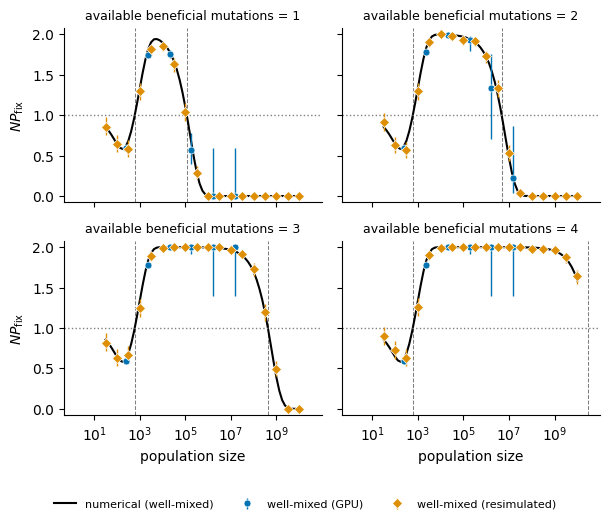

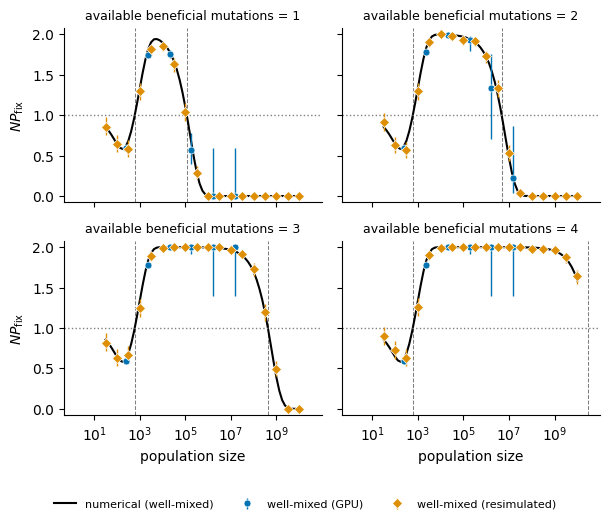

In [13]:
def plot_npfix(
    df_points: pd.DataFrame,
    Ks: list,
    treatments: list,
    palette: list,
    markers: list,
    col_wrap: int,
) -> plt.Figure:
    n_row = -(-len(Ks) // col_wrap)
    fig, axs = plt.subplots(
        n_row,
        col_wrap,
        figsize=(3.1 * col_wrap, 2.3 * n_row + 0.6),
        sharex=True,
        sharey=True,
        squeeze=False,
    )
    for ax, K in zip(axs.flat, Ks):
        theory = df_theory[df_theory["available beneficial mutations"] == K]
        ax.axhline(1.0, color="gray", lw=1, ls=":")
        for which in "lower Ncrit", "upper Ncrit":
            ncrit = df_ncrit_theory.set_index(
                "available beneficial mutations"
            ).loc[K, which]
            if np.isfinite(ncrit):
                ax.axvline(ncrit, color="black", lw=0.75, ls="--", alpha=0.5)
        ax.plot(
            theory["population size"],
            theory["NPfix"],
            color="black",
            lw=1.5,
            label="numerical (well-mixed)",
            zorder=1,
        )
        for treatment, color, marker in zip(treatments, palette, markers):
            points = df_points[
                (df_points["treatment"] == treatment)
                & (df_points["available beneficial mutations"] == K)
            ]
            if not len(points):
                continue
            ax.errorbar(
                points["population size"],
                points["NPfix"],
                yerr=[
                    points["NPfix"] - points["NPfix lo"],
                    points["NPfix hi"] - points["NPfix"],
                ],
                color=color,
                marker=marker,
                ms=5,
                mec="white",
                mew=0.5,
                ls="none",
                elinewidth=1,
                label=treatment,
                zorder=2,
            )
        ax.set_xscale("log")
        ax.set_ylim(-0.08, 2.08)
        ax.set_title(
            "available beneficial mutations = "
            + (f"{K:.0f}" if np.isfinite(K) else "unlimited"),
            fontsize=9,
        )
    for ax in axs[-1]:
        ax.set_xlabel("population size")
    for ax in axs[:, 0]:
        ax.set_ylabel(r"$N P_\mathrm{fix}$")
    for ax in axs.flat[len(Ks) :]:
        ax.set_visible(False)
    handles = {}
    for ax in axs.flat:
        for handle, label in zip(*ax.get_legend_handles_labels()):
            handles.setdefault(label, handle)
    fig.legend(
        handles.values(),
        handles.keys(),
        loc="lower center",
        ncol=min(len(handles), 3),
        frameon=False,
        fontsize=8,
    )
    sns.despine(fig)
    fig.tight_layout(rect=(0, 0.04 + 0.03 * (-(-len(handles) // 3)), 1, 1))
    return fig


df_points = pd.concat([df_data, df_resim], ignore_index=True)
palette = sns.color_palette("colorblind")
tp.tee(
    plot_npfix,
    df_points=df_points,
    Ks=[1, 2, 3, 4],
    treatments=["well-mixed (GPU)", "well-mixed (resimulated)"],
    palette=[palette[0], palette[1]],
    markers=["o", "D"],
    col_wrap=2,
    teeplot_outattrs={"what": "wellmixed"},
    teeplot_subdir=teeplot_subdir,
)


## Normalized Fixation Probability: Theory vs. Spatially Structured Data

Theory curves are for a well-mixed population; no spatial correction is applied.


teeplots/theory-5050-npfix/viz=plot-npfix+what=all+ext=.pdf
teeplots/theory-5050-npfix/viz=plot-npfix+what=all+ext=.png


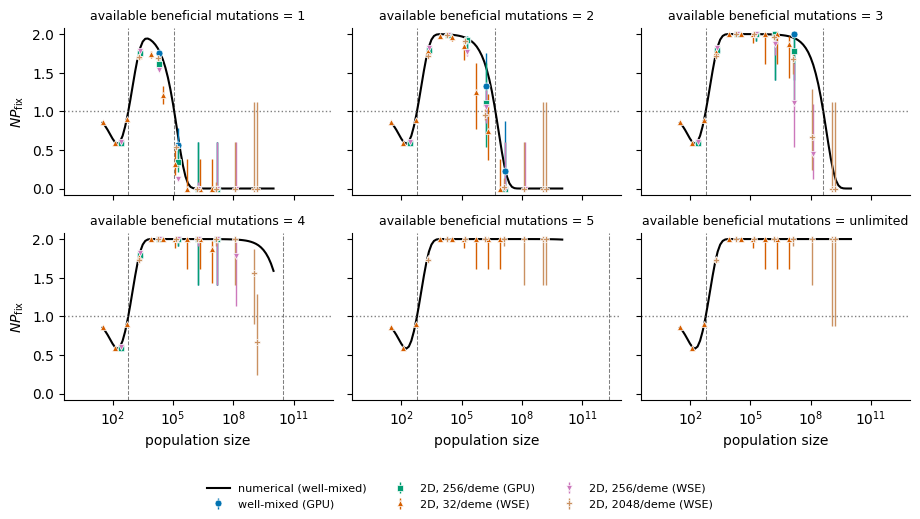

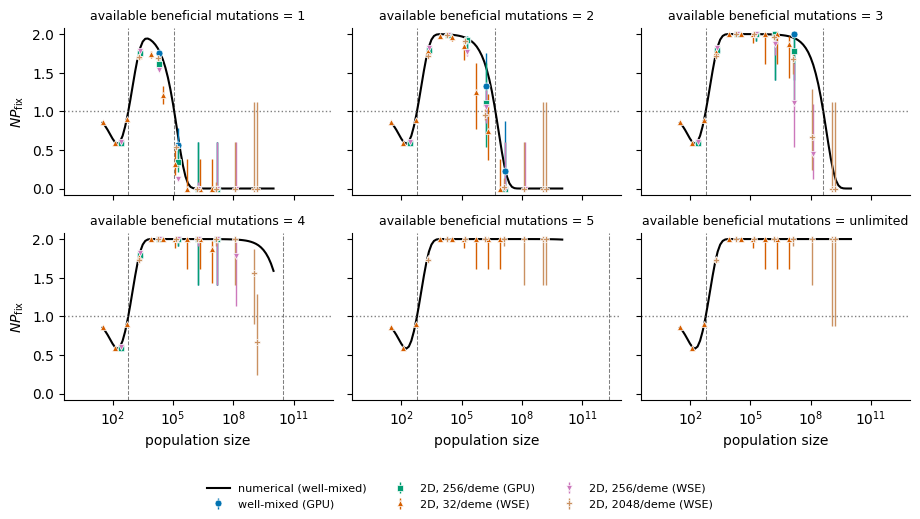

In [14]:
tp.tee(
    plot_npfix,
    df_points=df_points,
    Ks=[1, 2, 3, 4, 5, np.inf],
    treatments=[
        "well-mixed (GPU)",
        "2D, 256/deme (GPU)",
        "2D, 32/deme (WSE)",
        "2D, 256/deme (WSE)",
        "2D, 2048/deme (WSE)",
    ],
    palette=[palette[i] for i in (0, 2, 3, 4, 5)],
    markers=["o", "s", "^", "v", "P"],
    col_wrap=3,
    teeplot_outattrs={"what": "all"},
    teeplot_subdir=teeplot_subdir,
)


## Closed Form, with Population Structure

The closed-form model, for each population structure simulated.
Structure enters only through the sweep time; no parameter is fitted.


In [15]:
deme_sizes = {
    "well-mixed (GPU)": None,
    "2D, 256/deme (GPU)": 256,
    "2D, 32/deme (WSE)": 32,
    "2D, 2048/deme (WSE)": 2048,
    "2D, 256/deme (WSE)": 256,
}
df_theory_closed = pd.DataFrame(
    [
        {
            "treatment": treatment,
            "population size": 10**log_N,
            "available beneficial mutations": K,
            "fixation probability": calc_mutator_fixprob_closed(
                10**log_N, K, deme_size=deme_size
            ),
        }
        for (treatment, deme_size), K, log_N in it.product(
            deme_sizes.items(), [1, 2, 3, 4], np.arange(1.5, 10.01, 0.125)
        )
    ],
)
df_theory_closed["NPfix"] = df_theory_closed["fixation probability"] / 0.5
df_theory_closed


/home/runner/work/hypermutator-dynamics/hypermutator-dynamics/binder/pylib/theory/_calc_drift_fixprob.py:15: RuntimeWarning: overflow encountered in expm1
  return float(np.expm1(a * x0) / np.expm1(a))


,treatment,population size,available beneficial mutations,fixation probability,NPfix
0,well-mixed (GPU),3.162278e+01,1,0.443337,0.886673
1,well-mixed (GPU),4.216965e+01,1,0.426096,0.852191
2,well-mixed (GPU),5.623413e+01,1,0.404662,0.809325
3,well-mixed (GPU),7.498942e+01,1,0.379119,0.758238
4,well-mixed (GPU),1.000000e+02,1,0.350863,0.701726
...,...,...,...,...,...
1375,"2D, 256/deme (WSE)",3.162278e+09,4,0.923935,1.847870
1376,"2D, 256/deme (WSE)",4.216965e+09,4,0.899875,1.799749
1377,"2D, 256/deme (WSE)",5.623413e+09,4,0.868762,1.737524
1378,"2D, 256/deme (WSE)",7.498942e+09,4,0.828940,1.657879


teeplots/theory-5050-npfix/viz=plot-npfix-closed+ext=.pdf
teeplots/theory-5050-npfix/viz=plot-npfix-closed+ext=.png


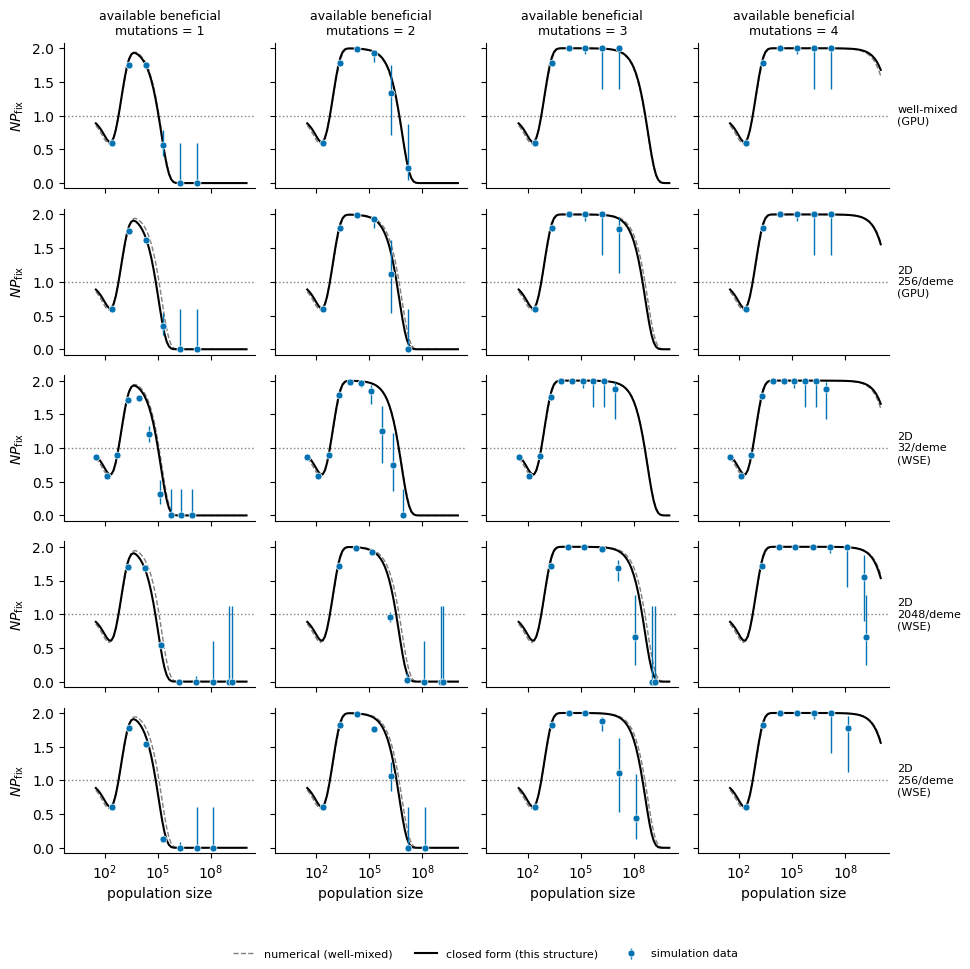

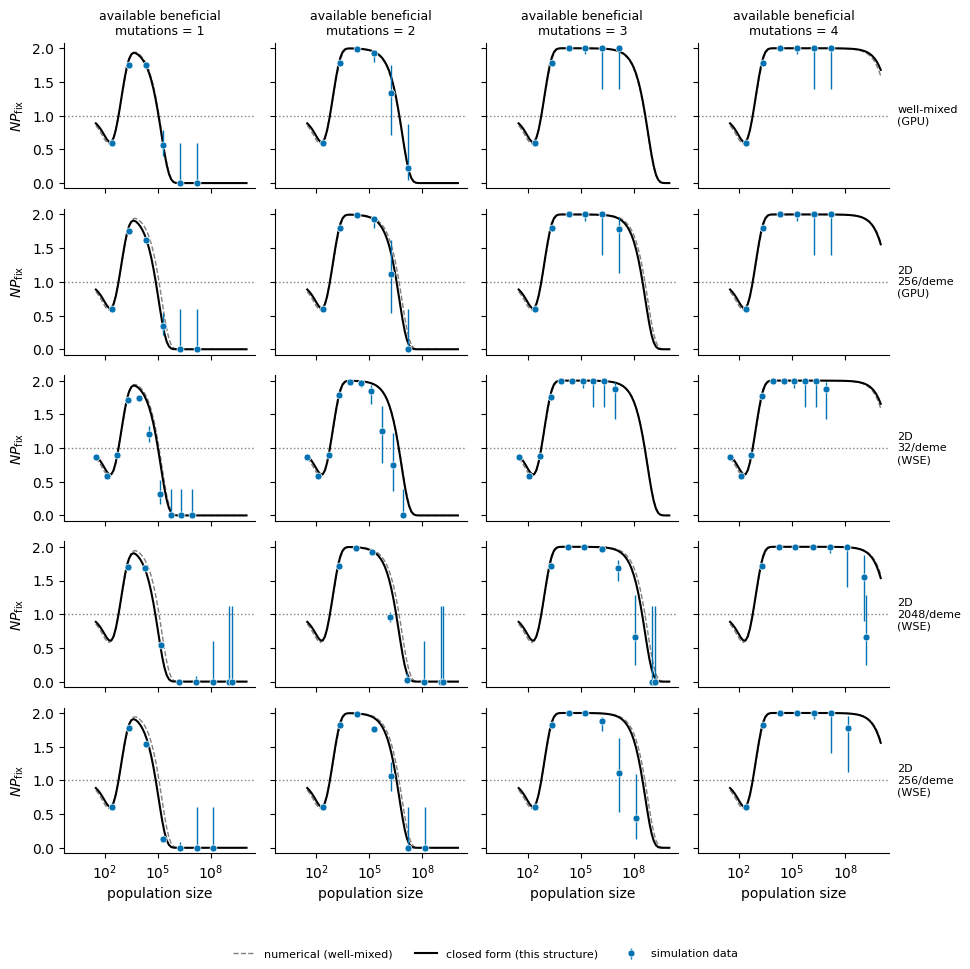

In [16]:
def plot_npfix_closed(
    df_points: pd.DataFrame,
    df_theory_closed: pd.DataFrame,
    Ks: list,
    treatments: list,
) -> plt.Figure:
    fig, axs = plt.subplots(
        len(treatments),
        len(Ks),
        figsize=(2.6 * len(Ks), 1.8 * len(treatments) + 0.7),
        sharex=True,
        sharey=True,
        squeeze=False,
    )
    color = sns.color_palette("colorblind")[0]
    for (treatment, K), ax in zip(it.product(treatments, Ks), axs.flat):
        ax.axhline(1.0, color="gray", lw=1, ls=":")
        numerical = df_theory[df_theory["available beneficial mutations"] == K]
        ax.plot(
            numerical["population size"],
            numerical["NPfix"],
            color="gray",
            lw=1,
            ls="--",
            label="numerical (well-mixed)",
        )
        closed = df_theory_closed[
            (df_theory_closed["treatment"] == treatment)
            & (df_theory_closed["available beneficial mutations"] == K)
        ]
        ax.plot(
            closed["population size"],
            closed["NPfix"],
            color="black",
            lw=1.5,
            label="closed form (this structure)",
        )
        points = df_points[
            (df_points["treatment"] == treatment)
            & (df_points["available beneficial mutations"] == K)
        ]
        ax.errorbar(
            points["population size"],
            points["NPfix"],
            yerr=[
                points["NPfix"] - points["NPfix lo"],
                points["NPfix hi"] - points["NPfix"],
            ],
            color=color,
            marker="o",
            ms=5,
            mec="white",
            mew=0.5,
            ls="none",
            elinewidth=1,
            label="simulation data",
        )
        ax.set_xscale("log")
        ax.set_ylim(-0.08, 2.08)
    for ax, K in zip(axs[0], Ks):
        ax.set_title(f"available beneficial\nmutations = {K}", fontsize=9)
    for ax, treatment in zip(axs[:, -1], treatments):
        ax.annotate(
            treatment.replace(", ", "\n").replace(" (", "\n("),
            xy=(1.04, 0.5),
            xycoords="axes fraction",
            fontsize=8,
            va="center",
        )
    for ax in axs[-1]:
        ax.set_xlabel("population size")
    for ax in axs[:, 0]:
        ax.set_ylabel(r"$N P_\mathrm{fix}$")
    fig.legend(
        *axs.flat[0].get_legend_handles_labels(),
        loc="lower center",
        ncol=3,
        frameon=False,
        fontsize=8,
    )
    sns.despine(fig)
    fig.tight_layout(rect=(0, 0.05, 0.93, 1))
    return fig


tp.tee(
    plot_npfix_closed,
    df_points=df_points,
    df_theory_closed=df_theory_closed,
    Ks=[1, 2, 3, 4],
    treatments=[*deme_sizes],
    teeplot_subdir=teeplot_subdir,
)


## Critical Population Sizes

Empirical $N_\mathrm{crit}$ are interpolated (linearly in $\log N$) between the pair of surveyed population sizes that bracket a 50/50 outcome.


In [17]:
def interpolate_ncrit(group: pd.DataFrame, which: str) -> float:
    group = group.sort_values("population size")
    log_N = np.log10(group["population size"].to_numpy(dtype=float))
    p = group["fixation probability"].to_numpy()
    above = p >= 0.5
    if which == "lower":
        (idx,) = np.nonzero(~above[:-1] & above[1:])
    else:
        (idx,) = np.nonzero(above[:-1] & ~above[1:])
    if not len(idx):
        return np.nan
    i = idx[0] if which == "lower" else idx[-1]
    frac = (0.5 - p[i]) / (p[i + 1] - p[i])
    return 10 ** (log_N[i] + frac * (log_N[i + 1] - log_N[i]))


records = []
for (treatment, K), group in df_points.groupby(
    ["treatment", "available beneficial mutations"],
):
    for which in "lower", "upper":
        records.append(
            {
                "treatment": treatment,
                "available beneficial mutations": K,
                "which": which,
                "Ncrit": interpolate_ncrit(group, which),
            },
        )
for __, row in df_ncrit_theory.iterrows():
    for which in "lower", "upper":
        records.append(
            {
                "treatment": "numerical (well-mixed)",
                "available beneficial mutations": row[
                    "available beneficial mutations"
                ],
                "which": which,
                "Ncrit": row[f"{which} Ncrit"],
            },
        )
for (label, deme_size), K, which in it.product(
    [
        ("closed form (well-mixed)", None),
        ("closed form (2D, 32/deme)", 32),
        ("closed form (2D, 256/deme)", 256),
        ("closed form (2D, 2048/deme)", 2048),
    ],
    [1, 2, 3, 4, 5],
    ["lower", "upper"],
):
    records.append(
        {
            "treatment": label,
            "available beneficial mutations": K,
            "which": which,
            "Ncrit": calc_ncrit_closed(K, which, deme_size=deme_size),
        },
    )
df_ncrit = pd.DataFrame(records).dropna()
with pd.option_context("display.float_format", "{:.3g}".format):
    display(
        df_ncrit.pivot(
            index=["which", "available beneficial mutations"],
            columns="treatment",
            values="Ncrit",
        ),
    )


treatment                             2D, 2048/deme (WSE)  2D, 256/deme (GPU)  \
which available beneficial mutations                                            
lower 1                                               NaN                 552   
      2                                               NaN                 537   
      3                                               NaN                 536   
      4                                               NaN                 536   
      5                                               NaN                 NaN   
      8                                               NaN                 536   
      10                                              NaN                 NaN   
      30                                              NaN                 NaN   
      inf                                             NaN                 NaN   
upper 1                                          6.42e+04            6.03e+04   
      2                                          1.34e+06            2.09e+06   
      3                                          5.87e+07                 NaN   
      4                                          1.34e+09                 NaN   
      5                                               NaN                 NaN   

treatment                             2D, 256/deme (WSE)  2D, 32/deme (WSE)  \
which available beneficial mutations                                          
lower 1                                              537                605   
      2                                              522                606   
      3                                              521                614   
      4                                              521                600   
      5                                              NaN                607   
      8                                              NaN                NaN   
      10                                             521                NaN   
      30                                             521                NaN   
      inf                                            NaN                605   
upper 1                                          4.8e+04           4.54e+04   
      2                                         1.91e+06           1.05e+06   
      3                                         2.18e+07                NaN   
      4                                              NaN                NaN   
      5                                              NaN                NaN   

treatment                             closed form (2D, 2048/deme)  \
which available beneficial mutations                                
lower 1                                                       603   
      2                                                       603   
      3                                                       603   
      4                                                       603   
      5                                                       603   
      8                                                       NaN   
      10                                                      NaN   
      30                                                      NaN   
      inf                                                     NaN   
upper 1                                                  7.18e+04   
      2                                                  3.27e+06   
      3                                                  2.91e+08   
      4                                                  2.62e+10   
      5                                                  2.36e+12   

treatment                             closed form (2D, 256/deme)  \
which available beneficial mutations                               
lower 1                                                      603   
      2                                                      603   
      3                                                      

teeplots/theory-5050-npfix/viz=plot-ncrit+ext=.pdf
teeplots/theory-5050-npfix/viz=plot-ncrit+ext=.png


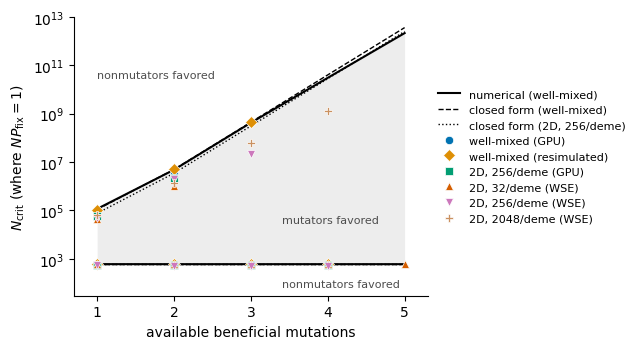

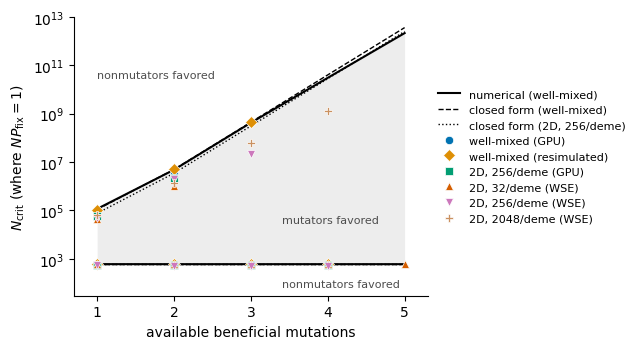

In [18]:
def plot_ncrit(df_ncrit: pd.DataFrame, treatments: list) -> plt.Figure:
    fig, ax = plt.subplots(figsize=(6.5, 3.6))
    palette = sns.color_palette("colorblind")
    colors = [palette[i] for i in (0, 1, 2, 3, 4, 5)]
    markers = ["o", "D", "s", "^", "v", "P"]
    theory = df_ncrit[df_ncrit["treatment"] == "numerical (well-mixed)"]
    finite = theory[np.isfinite(theory["available beneficial mutations"])]
    upper = finite[finite["which"] == "upper"]
    lower = finite[finite["which"] == "lower"]
    ax.fill_between(
        upper["available beneficial mutations"],
        lower["Ncrit"],
        upper["Ncrit"],
        color="black",
        alpha=0.07,
        lw=0,
    )
    for xy, text in (
        ((3.4, 3e4), "mutators favored"),
        ((1.0, 3e10), "nonmutators favored"),
        ((3.4, 70), "nonmutators favored"),
    ):
        ax.text(*xy, text, fontsize=8, color="0.3")
    for which, group in finite.groupby("which"):
        ax.plot(
            group["available beneficial mutations"],
            group["Ncrit"],
            color="black",
            lw=1.5,
            label="numerical (well-mixed)" if which == "lower" else None,
        )
    for label, ls in (
        ("closed form (well-mixed)", "--"),
        ("closed form (2D, 256/deme)", ":"),
    ):
        for which, group in df_ncrit[df_ncrit["treatment"] == label].groupby(
            "which"
        ):
            ax.plot(
                group["available beneficial mutations"],
                group["Ncrit"],
                color="black",
                lw=1,
                ls=ls,
                label=label if which == "lower" else None,
            )
    for treatment, color, marker in zip(treatments, colors, markers):
        points = df_ncrit[
            (df_ncrit["treatment"] == treatment)
            & np.isfinite(df_ncrit["available beneficial mutations"])
        ]
        ax.plot(
            points["available beneficial mutations"],
            points["Ncrit"],
            color=color,
            marker=marker,
            ms=6,
            mec="white",
            mew=0.5,
            ls="none",
            label=treatment,
        )
    ax.set_yscale("log")
    ax.set_xticks([1, 2, 3, 4, 5])
    ax.set_xlim(0.7, 5.3)
    ax.set_ylim(30, 1e13)
    ax.set_xlabel("available beneficial mutations")
    ax.set_ylabel(r"$N_\mathrm{crit}$ (where $N P_\mathrm{fix} = 1$)")
    ax.legend(
        frameon=False, fontsize=8, loc="center left", bbox_to_anchor=(1, 0.5)
    )
    sns.despine(fig)
    fig.tight_layout()
    return fig


tp.tee(
    plot_ncrit,
    df_ncrit=df_ncrit,
    treatments=[
        "well-mixed (GPU)",
        "well-mixed (resimulated)",
        "2D, 256/deme (GPU)",
        "2D, 32/deme (WSE)",
        "2D, 256/deme (WSE)",
        "2D, 2048/deme (WSE)",
    ],
    teeplot_subdir=teeplot_subdir,
)


## Quality Check: Theory vs. Well-mixed Fixation Probabilities


In [19]:
df_check = df_data[df_data["treatment"] == "well-mixed (GPU)"].copy()
df_check["error"] = (
    df_check["theory fixation probability"] - df_check["fixation probability"]
)
display(
    df_check[
        [
            "available beneficial mutations",
            "population size",
            "num replicates",
            "fixation probability",
            "theory fixation probability",
            "error",
        ]
    ],
)
df_check["error"].abs().max()


,available beneficial mutations,population size,num replicates,fixation probability,theory fixation probability,error
180,1.0,256,59049,0.297092,3.113392e-01,1.424694e-02
181,1.0,2304,6561,0.875324,9.049210e-01,2.959708e-02
182,1.0,20736,729,0.879287,8.913561e-01,1.206940e-02
183,1.0,186624,81,0.283951,3.252922e-01,4.134162e-02
184,1.0,1679616,9,0.000000,3.651891e-05,3.651891e-05
185,1.0,15116544,9,0.000000,1.030981e-40,1.030981e-40
186,2.0,256,59049,0.297600,3.114763e-01,1.387596e-02
187,2.0,2304,6561,0.888889,9.130540e-01,2.416515e-02
188,2.0,20736,729,0.993141,9.973460e-01,4.204668e-03
189,2.0,186624,81,0.962963,9.714577e-01,8.494759e-03


np.float64(0.11403233497586751)